In [6]:
import arff
import polars as pl
import matplotlib.pyplot as plt
import numpy as np

In [7]:
with open("../datasets/phishing-websites/Training Dataset.arff", "r") as file:
    dataset = arff.load(file)

In [8]:
column_names = [attribute[0] for attribute in dataset["attributes"]]

df = pl.DataFrame(
    dataset["data"],
    schema=column_names,
    orient="row"
)

In [9]:
df = df.with_columns(pl.all().cast(pl.Int64))
df.head()

having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,0,1,1,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1,-1
1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1,-1
1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1,-1
1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1,1


In [10]:
ssl_counts = (
    df.group_by("Result")
    .agg(
        pl.len().alias("total_websites"),
        (pl.col("SSLfinal_State") == 1).sum().alias("ssl_category_1"),
    )
    .sort("Result")
)

ssl_counts

Result,total_websites,ssl_category_1
i64,u32,u32
-1,4898,701
1,6157,5630


In [11]:
ssl_rates = ssl_counts.with_columns(
    (pl.col("ssl_category_1") / pl.col("total_websites") * 100)
    .round(2)
    .alias("percent_in_ssl_category_1")
)

ssl_rates

Result,total_websites,ssl_category_1,percent_in_ssl_category_1
i64,u32,u32,f64
-1,4898,701,14.31
1,6157,5630,91.44


In [12]:
ssl_by_length = (
    df.group_by(["URL_Length", "Result"])
    .agg(
        pl.len().alias("total_websites"),
        ((pl.col("SSLfinal_State") == 1).mean() * 100)
        .round(2)
        .alias("percent_in_ssl_category_1"),
    )
    .sort(["URL_Length", "Result"])
)

ssl_by_length

URL_Length,Result,total_websites,percent_in_ssl_category_1
i64,i64,u32,f64
-1,-1,4079,14.61
-1,1,4881,91.56
0,-1,83,16.87
0,1,52,100.0
1,-1,736,12.36
1,1,1224,90.6


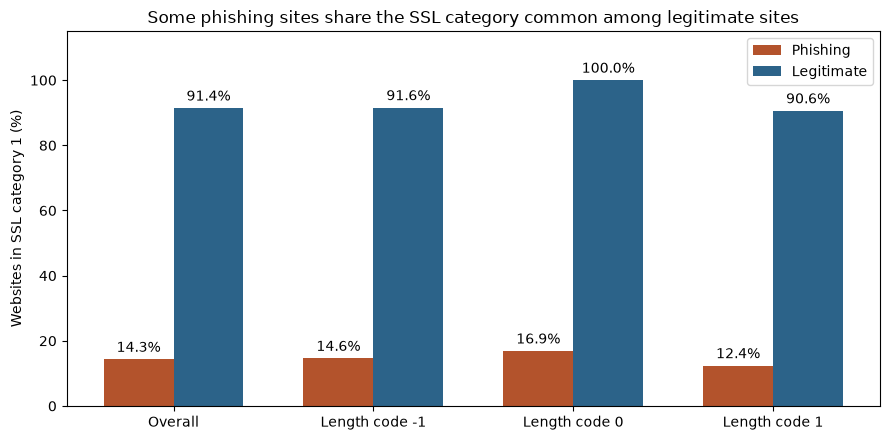

In [13]:
from pathlib import Path

rate = "percent_in_ssl_category_1"
labels = ["Overall", "Length code -1", "Length code 0", "Length code 1"]
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 4.5))

for result, name, offset, color in [
    (-1, "Phishing", -width / 2, "#B3532C"),
    (1, "Legitimate", width / 2, "#2C6389"),
]:
    overall = ssl_rates.filter(pl.col("Result") == result)[rate].to_list()
    by_length = ssl_by_length.filter(pl.col("Result") == result)[rate].to_list()
    bars = ax.bar(x + offset, overall + by_length, width, label=name, color=color)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)

ax.set_xticks(x, labels)
ax.set_ylabel("Websites in SSL category 1 (%)")
ax.set_ylim(0, 115)
ax.set_title("Some phishing sites share the SSL category common among legitimate sites")
ax.legend()
fig.tight_layout()

figure_dir = Path("../figures")
figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / "uci327-ssl-by-url-length.png", dpi=200, bbox_inches="tight")

plt.show()